In [1]:
import time
import torch
from torchvision import transforms as T, utils
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import io
import hydra
from omegaconf import DictConfig
import os
import sys
import deepwave
from deepwave import scalar
from torch.optim import Adam
from torchaudio.functional import biquad
from scipy.ndimage import gaussian_filter
from scipy.signal import butter
from torch import optim
import sys
from utils.utils import *

In [2]:
####   MAIN PARAMETERS FOR FORWARD MODELING         ####
####################################################
dx        = 12.5                  # step interval along x/z direction
dt        = 0.003                # time interval (e.g., 3ms)
num_dims  = 2                     # dimension of velocity model
nz        = 281                  # model shape of z dimension (depth) Marmousi2
ny        = 1361                   # model shape of y dimension Marmousi2
vmodel_dim = np.array([nz, ny])

total_t   = 6                      # totle sampling time (unit: s)
nt        = int(total_t / dt)       # number of time sampling points
num_shots = 68                  # nunmber of shots
num_sources_per_shot = 1            # number of sources per shot
num_receivers_per_shot = 1361        # number of receivers per shot

source_spacing=20 ###this is the number of grid not the real distance 6:dx*6=150m
receiver_spacing=1 ###this is the number of grid not the real distance 1=25m

source_depth = 0                # the index depth of sources, default is 0
receiver_depth = 0              # the index depths of receivers, default is 0
order          = 8              # precision order of finite difference in space domain
fwi_lr            = 2       # learning rate for updating the model.
fwi_batch         = num_shots     # number of batches for FWI.
fwi_num_epochs    = 30   # number of FWI iteration test
sim_lr            = 1*1e-4    # learning rate for Siamese network.
survey_pad = None
savepoch = 50                 # Saving models each 50 FWI iterations
first_source=0
n_sources_per_shot=1
first_receiver=0

Text(0.5, 1.0, 'Initial')

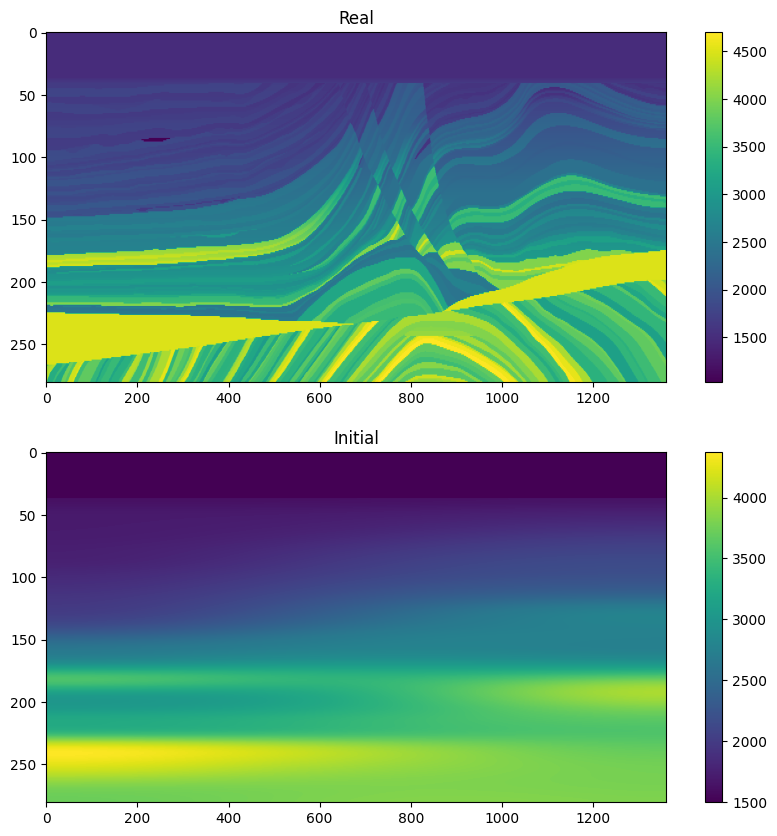

In [3]:
torch.backends.cudnn.enabled = True     ######activate CUDNN
torch.backends.cudnn.benchmark = True   ######select the optimal optimization method

cuda_available = torch.cuda.is_available()
device = torch.device("cuda:0" if cuda_available else "cpu")

directadd=os.path.join(os.getcwd())
data_path = directadd+'/data_marmall/vel_marm_281_1361.bin'             ####real model
initfile = directadd+'/data_marmall/mymar_initmodel_281_1361.mat'       ####initial model
initsafile = directadd+'/data_marmall/mar_big_initsource.mat'           ####source

fwi_result = directadd+'/results_marmall/Marmousi2/'

model_true = loadtruemodel(data_path, num_dims, vmodel_dim).to(device)

model, model_init = loadinitmodel(initfile,device)

model = torch.nn.Parameter(model)


plt.figure(figsize=(10,10))
plt.subplot(2,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Real")
plt.subplot(2,1,2)
plt.imshow(model.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Initial")


In [4]:
# Creating source and reciver locations

source_locations = torch.zeros(
            num_shots, n_sources_per_shot, 2, dtype=torch.long, device=device
        )
source_locations[..., 1] = source_depth

source_locations[:, 0, 0] = torch.arange(num_shots) * source_spacing + first_source

receiver_locations = torch.zeros(
            num_shots, num_receivers_per_shot, 2, dtype=torch.long, device=device
        )
receiver_locations[..., 1] = receiver_depth
receiver_locations[:, :, 0] = (
            (torch.arange(num_receivers_per_shot) * receiver_spacing + first_receiver).repeat(num_shots, 1)
        )

# Setup source amplitudes

source_amplitudes_init, source_amplitudes_true = loadinitsource(initsafile,device)
source = source_amplitudes_init.repeat(1,num_shots, num_sources_per_shot).permute(1,0,2).permute(0,2,1)


Text(0.5, 1.0, 'Shots')

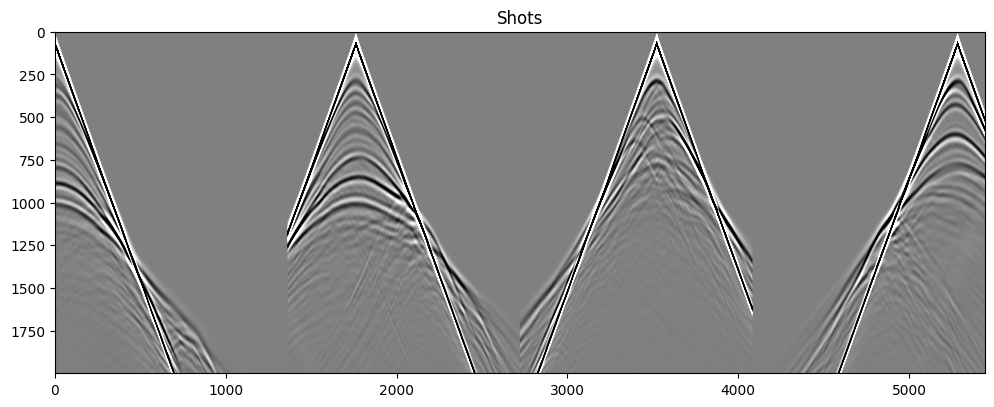

In [5]:
out = deepwave.scalar(model_true.T, dx, dt, source_amplitudes=source,
             source_locations=source_locations,
             receiver_locations=receiver_locations,
             accuracy=8,         
             pml_width=[10,10,10,10]) ################## 

rcv_amps_true = out[-1].permute(2,0,1)

plt.figure(figsize=(12,10))
plt.imshow(rcv_amps_true[:,::20,:].detach().cpu().numpy().reshape(rcv_amps_true[:,::20,:].shape[0],rcv_amps_true[:,::20,:].shape[1]*rcv_amps_true[:,::20,:].shape[2]),cmap='gray',vmin=-1,vmax=1)
plt.title('Shots')


In [6]:
from torchsummary import summary
from Model.Module22 import *

### optimizer for the velocity model
optimizer = optim.Adam([{'params': model, 'lr':fwi_lr, 'betas':(0.5, 0.9), 'eps':1e-8, 'weight_decay':0}])  #####The model here is initial model

leak_value = 0
D1 = 1
netD = SiameseNetwork(D1)
### init the hyper-parameters of netD ###
netD.apply(lambda m: weights_init(m, leak_value))  ###parameter initialization
netD = netD.to(device)

# Optimizer for Siamese network.
optim_s = optim.Adam(netD.parameters(),lr=sim_lr,betas=(0.5, 0.9), \
                    eps=1e-8, weight_decay=0)


In [7]:
############## Init  ################# 
SNR = 0.0
SSIM = 0.0
Loss = 0.0
ERROR = 0.0

import torch.nn.functional as F
# Starting the FWI loop

t_start = time.time()

fwi_num_epochs=60

# number of shots per batch
num_shots_per_batch = int(num_shots / fwi_batch)  #####30/30
for i in range(fwi_num_epochs):
    # initialization of the loss
    epoch_loss = 0.0
    for it in range(fwi_batch):
    
        iteration = i*fwi_batch+it+1
        # Set both optimizers to zero grad.
        optimizer.zero_grad()
        netD.train()                
        netD.zero_grad() 
      
        batch_src_amps = source_amplitudes_init.repeat(1, num_shots_per_batch, 1).permute(1,0,2).permute(0,2,1)

        batch_rcv_amps_true = rcv_amps_true[:,it::fwi_batch].to(device)
        

        
        batch_x_s = source_locations[it::fwi_batch].to(device)
        batch_x_r = receiver_locations[it::fwi_batch].to(device)

        

        outpre = deepwave.scalar(model.T, dx, dt, source_amplitudes=batch_src_amps,
             source_locations=batch_x_s,
             receiver_locations=batch_x_r,
             accuracy=8,         
             pml_width=[10,10,10,10])

        batch_rcv_amps_pred = outpre[-1].permute(2,0,1)
       

        if i<=30:
              # Prepare the data for Siamese network.
              batch_rcv_amps_true1=batch_rcv_amps_true.clone()
              batch_rcv_amps_true1[1501:2000,:,:]=0
              d_real = (batch_rcv_amps_true1).permute(1,0,2)
        
              d_real = d_real.unsqueeze(1)
        
              # train with fake data
              batch_rcv_amps_pred1=batch_rcv_amps_pred.clone()
              batch_rcv_amps_pred1[1501:2000,:,:]=0
              d_fake = (batch_rcv_amps_pred1).permute(1,0,2)
    
              d_fake = d_fake.unsqueeze(1)

        if i>30:
             # Prepare the data for Siamese network.
              batch_rcv_amps_true1=batch_rcv_amps_true.clone()
            
              d_real = (batch_rcv_amps_true1).permute(1,0,2)

              d_real = d_real.unsqueeze(1)

              batch_rcv_amps_pred1=batch_rcv_amps_pred.clone()
              d_fake = (batch_rcv_amps_pred1).permute(1,0,2)
    
              d_fake = d_fake.unsqueeze(1)

      

        disc_fake, disc_real, o1, o2 = netD(d_fake,d_real)
        # Measure the Eculedian Loss.
    
        
        loss =   F.pairwise_distance(o1, d_real, keepdim = True).mean()  
        
       
        epoch_loss += loss.item()
        loss.backward()
        # Updating the Siamese network.
        optim_s.step()
        
        # Clips gradient value of model
        torch.nn.utils.clip_grad_value_(model,1e3) 
        

        model.grad[0:37,:]=0 

        optimizer.step()
        # clip the model value that keep the minimum value is larger than 0        
        model.data=torch.clamp(model.data,min=950)     
    


    
    Loss = np.append(Loss, epoch_loss / fwi_batch)

    # compute the SNR and SSIM
    snr = ComputeSNR(model.detach().cpu().numpy(),  
              model_true.detach().cpu().numpy())
    SNR = np.append(SNR, snr)

    ssim = ComputeSSIM(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    SSIM = np.append(SSIM, ssim)

    rerror = ComputeRE(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    ERROR = np.append(ERROR, rerror)

    print('Epoch:', i+1, 'Loss: ', epoch_loss / fwi_batch, 'SNR:', snr, 'SSIM:', ssim.cpu().detach().cpu().numpy())
   
# Estimating the FWI time
t_end = time.time()
elapsed_time = t_end - t_start
print('Running complete in {:.0f}m  {:.0f}s' .format(elapsed_time //60 , elapsed_time % 60))

Epoch: 1 Loss:  49.84747673483456 SNR: 17.776878 SSIM: 0.2473622
Epoch: 2 Loss:  42.950275477241064 SNR: 17.709806 SSIM: 0.24186002
Epoch: 3 Loss:  35.05728634665994 SNR: 17.655151 SSIM: 0.2317214
Epoch: 4 Loss:  26.881500272189868 SNR: 17.623936 SSIM: 0.22062874
Epoch: 5 Loss:  21.312574849409216 SNR: 17.602657 SSIM: 0.21807984
Epoch: 6 Loss:  18.06216892074136 SNR: 17.589043 SSIM: 0.21944456
Epoch: 7 Loss:  15.446792728760663 SNR: 17.589462 SSIM: 0.22189738
Epoch: 8 Loss:  13.401932898689719 SNR: 17.60917 SSIM: 0.22533879
Epoch: 9 Loss:  11.793259676764993 SNR: 17.655025 SSIM: 0.22986178
Epoch: 10 Loss:  10.438335446750417 SNR: 17.727663 SSIM: 0.23689005
Epoch: 11 Loss:  9.286534835310544 SNR: 17.820929 SSIM: 0.24721755
Epoch: 12 Loss:  8.199062151067396 SNR: 17.934757 SSIM: 0.25925118
Epoch: 13 Loss:  7.1502110958099365 SNR: 18.066963 SSIM: 0.2723275
Epoch: 14 Loss:  6.153422594070435 SNR: 18.21306 SSIM: 0.2866587
Epoch: 15 Loss:  5.242502591189216 SNR: 18.368742 SSIM: 0.3025572
Epo

Text(0.5, 1.0, 'DL')

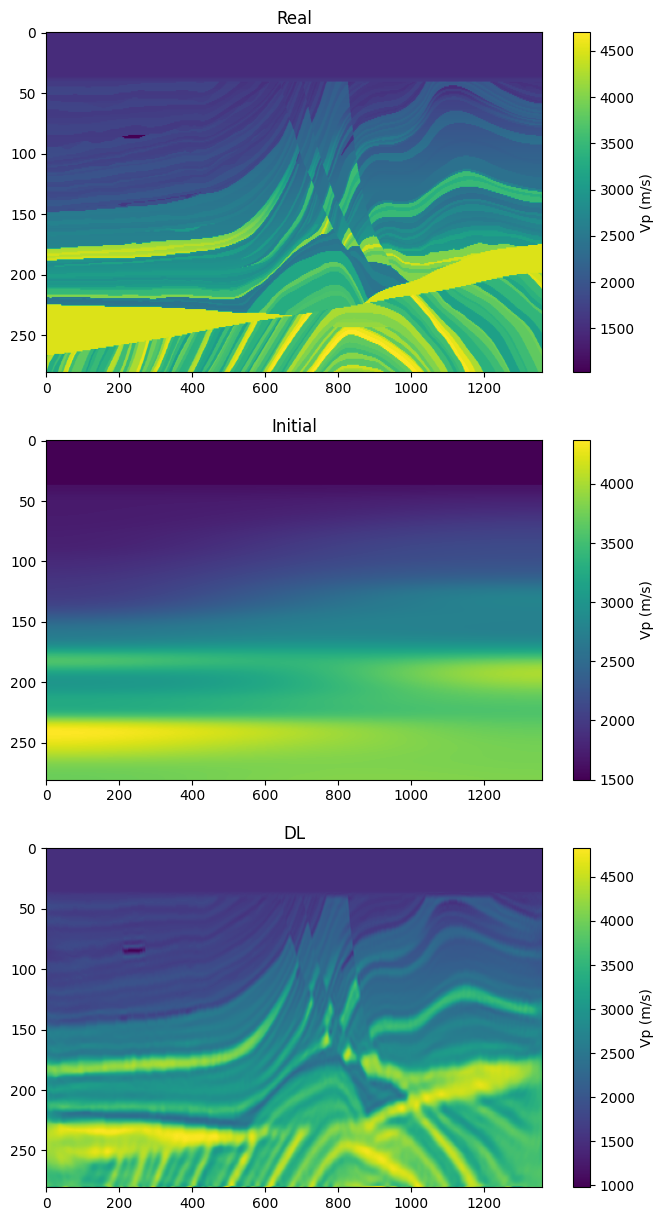

In [8]:
plt.figure(figsize=(8,15))
plt.subplot(3,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto')
plt.colorbar(label="Vp (m/s)")
plt.title("Real")
plt.subplot(3,1,2)
plt.imshow(model_init.detach().cpu().numpy(),aspect='auto')
plt.colorbar(label="Vp (m/s)")
plt.title("Initial")
plt.subplot(3,1,3)
plt.imshow(model.detach().cpu().numpy(),aspect='auto')
plt.colorbar(label="Vp (m/s)")
plt.title("DL")